# **ASSIGNMENT 1 – FIR FILTER DESIGN**

### **1. Thiết kế bộ lọc FIR Thông Thấp (Low-pass)**

#### Yêu cầu:
- fc = 50 Hz
- fs = 1024 Hz
- N = 1024
- Phương pháp: Cửa sổ Blackman

#### Mục đích:
- Giữ lại thành phần tần số thấp (10 Hz)
- Loại bỏ thành phần tần số cao (100 Hz)

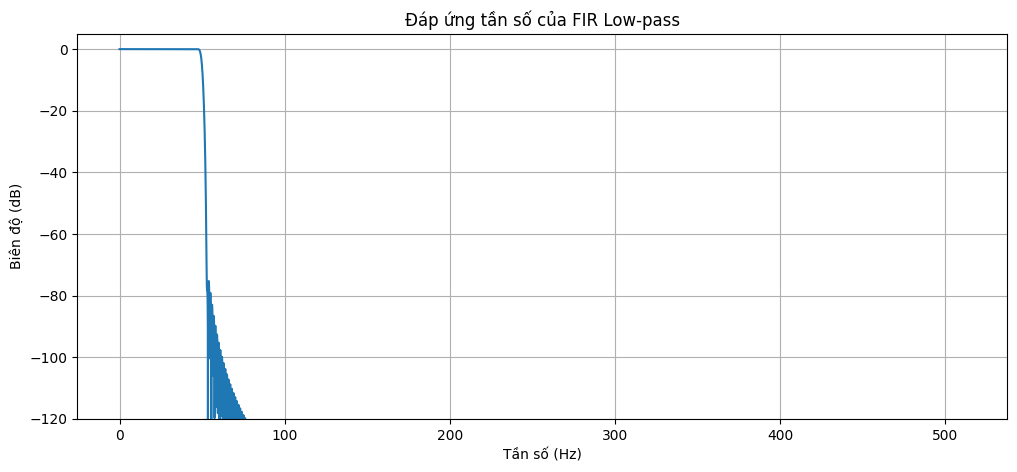

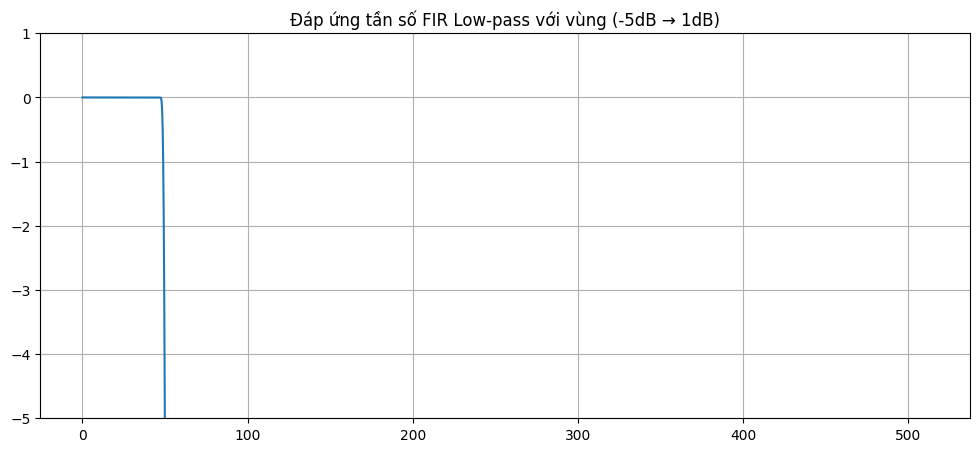

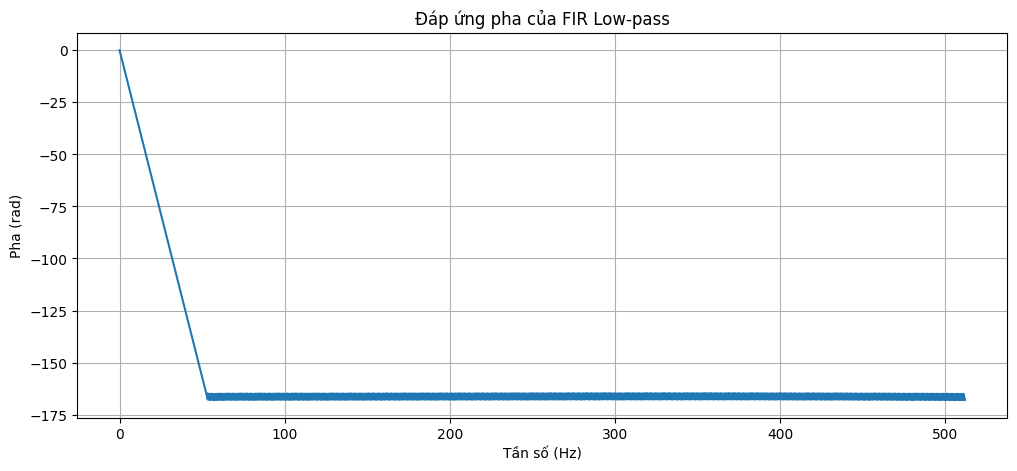

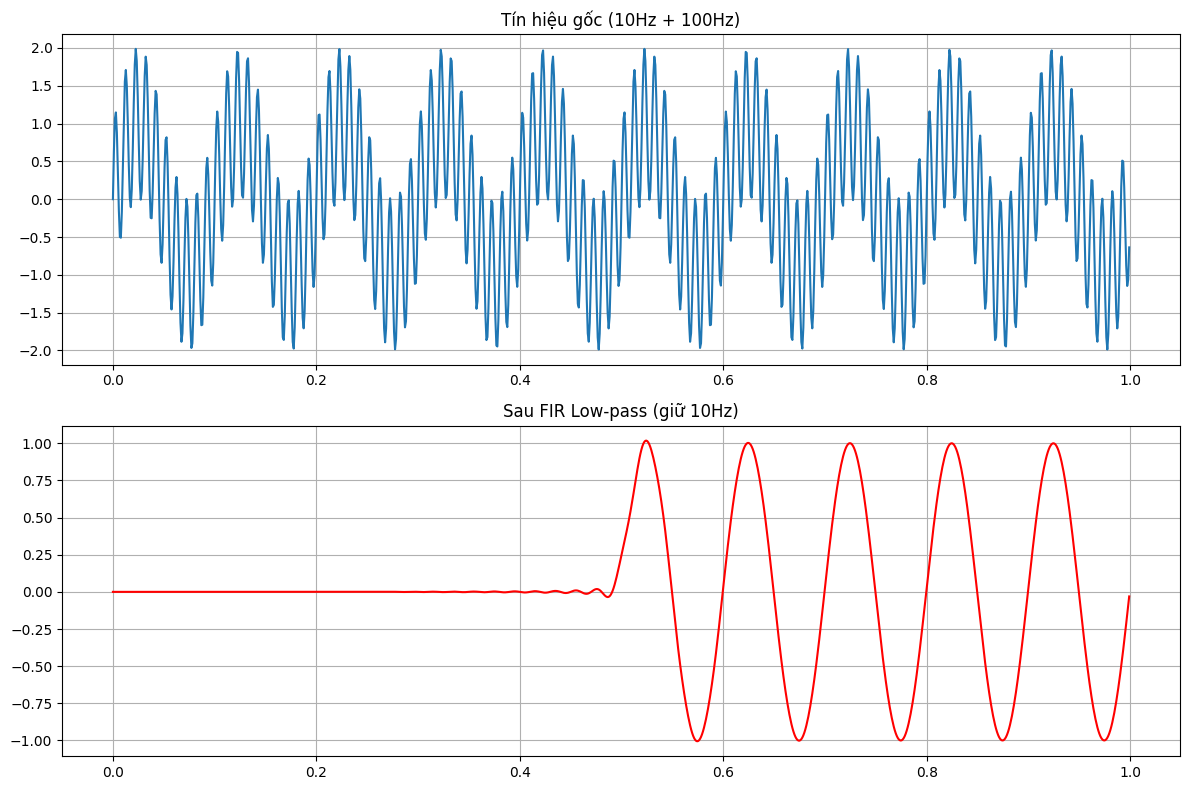

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz, lfilter

# Thông số chung
N = 1024
fs = 1024
fc = 50

# Low-pass (giữ dưới 50Hz)
b_lp = firwin(N, cutoff=fc, window="blackman", pass_zero=True, fs=fs)

w_lp, h_lp = freqz(b_lp, worN=8000, fs=fs)

# Đáp ứng tần số
plt.figure(figsize=(12, 5))
plt.plot(w_lp, 20 * np.log10(np.maximum(np.abs(h_lp), 1e-12)))
plt.title("Đáp ứng tần số của FIR Low-pass")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ (dB)")
plt.ylim(-120, 5)
plt.grid(True)
plt.show()

# Đáp ứng tần số với vùng quan sát -5 → 1 dB
plt.figure(figsize=(12, 5))
plt.plot(w_lp, 20 * np.log10(np.maximum(np.abs(h_lp), 1e-12)))
plt.title("Đáp ứng tần số FIR Low-pass với vùng (-5dB → 1dB)")
plt.ylim(-5, 1)
plt.grid(True)
plt.show()

# Đáp ứng pha
plt.figure(figsize=(12, 5))
plt.plot(w_lp, np.unwrap(np.angle(h_lp)))
plt.title("Đáp ứng pha của FIR Low-pass")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Pha (rad)")
plt.grid(True)
plt.show()

# Tạo tín hiệu mẫu
t = np.linspace(0, 1, fs, endpoint=False)
x = np.sin(2 * np.pi * 10 * t) + np.sin(2 * np.pi * 100 * t)

y_lp = lfilter(b_lp, 1.0, x)

plt.figure(figsize=(12, 8))
plt.subplot(2, 1, 1)
plt.plot(t, x)
plt.title("Tín hiệu gốc (10Hz + 100Hz)")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, y_lp, color="red")
plt.title("Sau FIR Low-pass (giữ 10Hz)")
plt.grid(True)

plt.tight_layout()
plt.show()

### **2. Thiết kế bộ lọc FIR Thông Cao (High-pass)**

#### Yêu cầu:
- fc = 50 Hz
- fs = 1024 Hz
- N = 1024
- Phương pháp: Cửa sổ Hamming

#### Lưu ý:
Do N = 1024 là số chẵn, bộ lọc high-pass không thể thiết kế trực tiếp bằng firwin(pass_zero=False).
Vì vậy sử dụng phương pháp **Spectral Inversion**:

h_hp[n] = δ[n] − h_lp[n]

để đảm bảo tính hợp lệ tại tần số Nyquist.

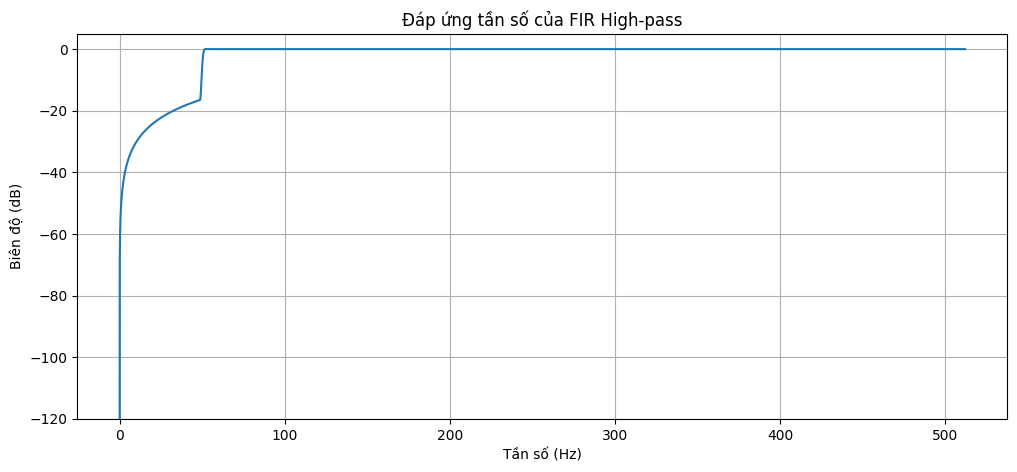

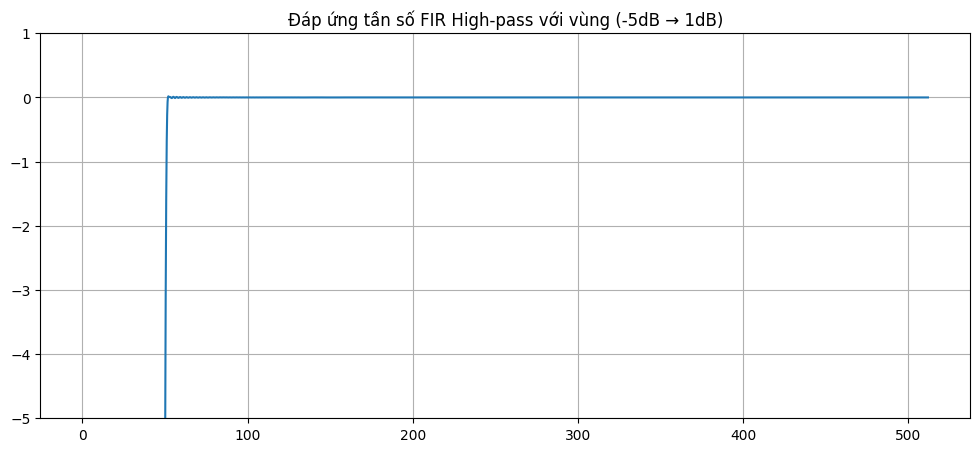

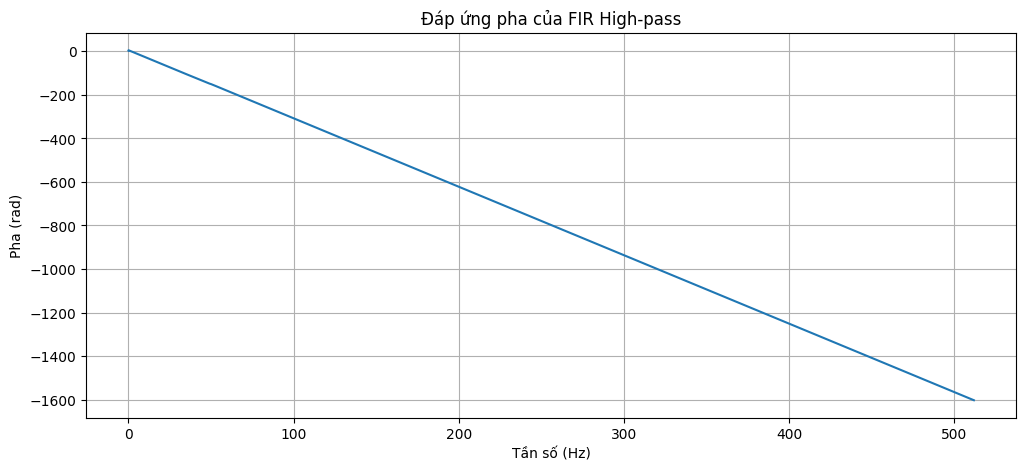

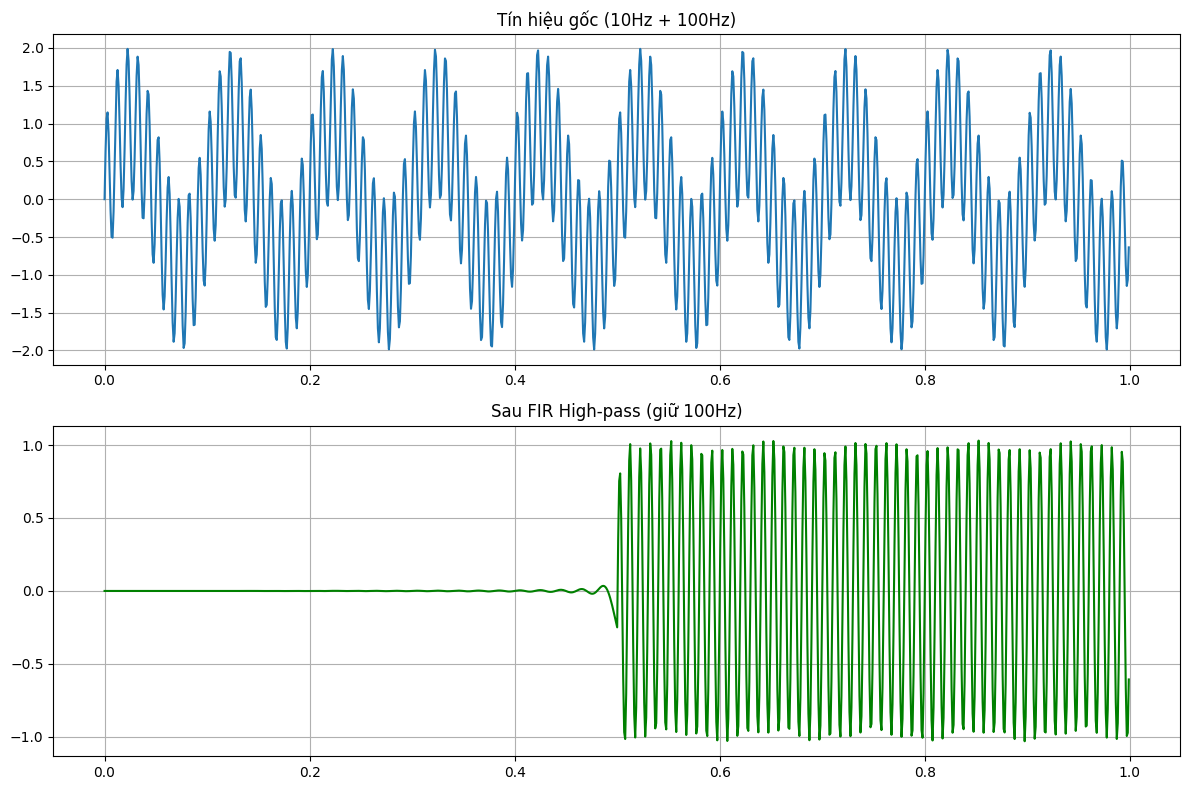

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz, lfilter

# Thông số chung
N = 1024
fs = 1024
fc = 50

# High-pass (giữ trên 50Hz)
# Thiết kế low-pass trung gian
b_temp = firwin(N, cutoff=fc, window="hamming", pass_zero=True, fs=fs)

# Spectral inversion
b_hp = -b_temp
b_hp[N // 2] += 1

w_hp, h_hp = freqz(b_hp, worN=8000, fs=fs)

# Đáp ứng tần số
plt.figure(figsize=(12, 5))
plt.plot(w_hp, 20 * np.log10(np.maximum(np.abs(h_hp), 1e-12)))
plt.title("Đáp ứng tần số của FIR High-pass")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ (dB)")
plt.ylim(-120, 5)
plt.grid(True)
plt.show()

# Đáp ứng tần số với vùng quan sát -5 → 1 dB
plt.figure(figsize=(12, 5))
plt.plot(w_hp, 20 * np.log10(np.maximum(np.abs(h_hp), 1e-12)))
plt.title("Đáp ứng tần số FIR High-pass với vùng (-5dB → 1dB)")
plt.ylim(-5, 1)
plt.grid(True)
plt.show()

# Đáp ứng pha
plt.figure(figsize=(12, 5))
plt.plot(w_hp, np.unwrap(np.angle(h_hp)))
plt.title("Đáp ứng pha của FIR High-pass")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Pha (rad)")
plt.grid(True)
plt.show()

# Tạo tín hiệu mẫu
t = np.linspace(0, 1, fs, endpoint=False)
x = np.sin(2 * np.pi * 10 * t) + np.sin(2 * np.pi * 100 * t)

y_hp = lfilter(b_hp, 1.0, x)

plt.figure(figsize=(12, 8))
plt.subplot(2, 1, 1)
plt.plot(t, x)
plt.title("Tín hiệu gốc (10Hz + 100Hz)")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, y_hp, color="green")
plt.title("Sau FIR High-pass (giữ 100Hz)")
plt.grid(True)

plt.tight_layout()
plt.show()